# Inicio del proyecto con UCI HAR 6 actividades

Características de sensores; investiguen el aporte de la información del giroscopio.

Este notebook carga los datos y explica su estructura. **No es una solución del proyecto.** Completen las secciones de investigación del final. Trabajen en Colab gratuito.

Fuente: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

## 1. Cargar los datos
Descompriman la entrega en su computador y abran este `.ipynb` en Colab. Ejecuten la siguiente celda y suban **ML_2026_11_10_UCI_HAR_6_actividades_DATOS.zip**, ubicado junto a este notebook. No suban el paquete general ni vuelvan a descargar la fuente original. La carga no necesita GPU.

In [1]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

archivo = Path('data/UCI_HAR_6_actividades.zip')
if not archivo.exists():
    from google.colab import files
    subidos = files.upload()
    if archivo.name not in subidos:
        raise ValueError("Sube el ZIP de DATOS que indica este notebook, con su nombre original.")

paquete = zipfile.ZipFile(archivo)
def leer_auxiliar(nombre):
    """Devuelve bytes de un archivo auxiliar incluido en este ZIP."""
    return io.BytesIO(paquete.read(nombre))

datos = np.load(leer_auxiliar('ML_2026_11_10_UCI_HAR_6_actividades_arrays.npz'), allow_pickle=False)
X, y = datos['X'], datos['y']
ids, split, nombres = datos['ids'], datos['split'], datos['names']
print('X:', X.shape, X.dtype, '| y:', y.shape)
print(dict(enumerate(nombres)))

X: (10299, 561) float32 | y: (10299,)
{0: np.str_('Caminar'), 1: np.str_('Subir escaleras'), 2: np.str_('Bajar escaleras'), 3: np.str_('Sentarse'), 4: np.str_('Estar de pie'), 5: np.str_('Acostarse')}


In [2]:
print("Eindeutige Splits:", np.unique(split, return_counts=True))
print("Anzahl eindeutiger Probanden (ids):", len(np.unique(ids)), "->", np.unique(ids))
print("Klassenverteilung in y:", np.unique(y, return_counts=True))
print("NaN-Werte in X:", np.isnan(X).sum())

Eindeutige Splits: (array(['test', 'train', 'val'], dtype='<U5'), array([2947, 5176, 2176]))
Anzahl eindeutiger Probanden (ids): 10299 -> [    0     1     2 ... 10296 10297 10298]
Klassenverteilung in y: (array([0, 1, 2, 3, 4, 5]), array([1722, 1544, 1406, 1777, 1906, 1944]))
NaN-Werte in X: 0


## 2. Respetar las particiones
Cada fila de `X`, `y`, `ids` y `split` corresponde a la misma observación. `y` es una etiqueta entera desde cero. Los identificadores y las etiquetas no son predictores. Usen `train` para aprender parámetros y transformaciones, `val` para elegir modelos y `test` para la evaluación final. La tabla de tamaños no evalúa ningún modelo.

In [3]:
# Identificar los ejemplos de cada partición
train = split == 'train'
val = split == 'val'
test = split == 'test'

# Separar las características
X_train = X[train]
X_val = X[val]
X_test = X[test]

# Separar las etiquetas
y_train = y[train]
y_val = y[val]
y_test = y[test]

# Mostrar el tamaño de cada conjunto
print("Ejemplos de entrenamiento:", len(y_train))
print("Ejemplos de validación:", len(y_val))
print("Ejemplos de test:", len(y_test))

Ejemplos de entrenamiento: 5176
Ejemplos de validación: 2176
Ejemplos de test: 2947


## 3. Escalar sin fuga de información
Las características ya están calculadas. El ejemplo ajusta un escalador **solo con entrenamiento** y transforma después validación y test. No vuelvan a ajustar el escalador sobre el conjunto completo. Para cada representación alternativa ajusten su propio escalador de entrenamiento. Los árboles no requieren este escalado.

In [4]:
from sklearn.preprocessing import StandardScaler
escalador = StandardScaler()
X_train_scaled = escalador.fit_transform(X_train).astype('float32')
X_val_scaled = escalador.transform(X_val).astype('float32')
X_test_scaled = escalador.transform(X_test).astype('float32')
print('Entrada preparada para MLP:', X_train_scaled.shape)

Entrada preparada para MLP: (5176, 561)


### Personas y grupos de variables
Las ventanas de una persona permanecen en una sola partición. Este control es esencial porque las ventanas no son observaciones independientes. Las 561 variables oficiales ya resumen señales; no estamos entrenando una red temporal. El ejemplo selecciona variables cuyo nombre contiene `Acc` y no `Gyro`; revisen la lista y el archivo de descripción para justificar qué consideran aceleración y cómo tratan variables mixtas.

In [5]:
# Identificador de la persona correspondiente a cada ejemplo
subject = datos['subject']

# Personas presentes en cada partición
personas_train = np.unique(subject[train])
personas_val = np.unique(subject[val])
personas_test = np.unique(subject[test])

print("Personas en entrenamiento:", personas_train)
print("Personas en validación:", personas_val)
print("Personas en test:", personas_test)

# Estas tres listas deben salir vacías
print("Personas compartidas entre train y val:",
      np.intersect1d(personas_train, personas_val))

print("Personas compartidas entre train y test:",
      np.intersect1d(personas_train, personas_test))

print("Personas compartidas entre val y test:",
      np.intersect1d(personas_val, personas_test))

Personas en entrenamiento: [ 1  3  5  7  8 11 14 16 17 19 21 22 25 28 29]
Personas en validación: [ 6 15 23 26 27 30]
Personas en test: [ 2  4  9 10 12 13 18 20 24]
Personas compartidas entre train y val: []
Personas compartidas entre train y test: []
Personas compartidas entre val y test: []


## 4. Desarrollar la investigación
Completen las siguientes secciones con texto, código y resultados. Consulten el enunciado y las rúbricas. No es necesario aplicar todas las ideas propuestas. Seleccionen una pregunta y una comparación que puedan justificar.

## Pregunta e hipótesis
¿Qué quieren averiguar y qué cambio observable esperan?

Research Question:
How much does adding gyroscope and angular velocity features (561 features total) improve human activity classification performance compared to using accelerometer-only features (343 features) in a Multi-Layer Perceptron (MLP)?

Hypothesis:
Including gyroscope features will measurably improve overall test accuracy and macro F1-score compared to the accelerometer-only baseline. Specifically, we expect the largest gains in:

1. Dynamic locomotion activities (Caminar, Subir escaleras, Bajar escaleras), where angular velocity captures rotational torso and leg movements that linear acceleration alone cannot fully distinguish.

2. Fine-grained postural distinctions (Sentarse vs. Estar de pie), where subtle orientation changes help reduce confusion, whereas Acostarse is already well separated by gravity acceleration alone.

Evaluation Criterion:
Our hypothesis will be supported if the MLP trained on all 561 features achieves a higher test macro F1-score and reduces false positives/negatives in the confusion matrix for dynamic activities and Sentarse/Estar de pie compared to the identical MLP trained on the 343 accelerometer features.

#### We want to investigate if the Gyro data improves the movement detection and by how much. The hypothesis is that including the Gyro data should improve the movement classification especially between standing and lying 

## Exploración y decisiones
¿Qué evidencia justifica su representación, preprocesamiento y métricas?

In [6]:
acc_ranges = [
    range(1, 121),    # tBodyAcc, tGravityAcc, tBodyAccJerk (1–120)
    range(201, 240),  # tBodyAccMag, tGravityAccMag, tBodyAccJerkMag (201–239)
    range(266, 424),  # fBodyAcc, fBodyAccJerk (266–423)
    range(503, 529),  # fBodyAccMag, fBodyBodyAccJerkMag (503–528)
    # Optional: reine Acc-Winkel am Ende (555, 556, 560, 561)
]

# In 0-basierte Python-Indizes umwandeln
acc_idx = [col - 1 for r in acc_ranges for col in r]

X_train_acc = X_train_scaled[:, acc_idx]
X_val_acc = X_val_scaled[:, acc_idx]
X_test_acc = X_test_scaled[:, acc_idx]
print("Shape von X_train_acc:", X_train_acc.shape)

Shape von X_train_acc: (5176, 343)


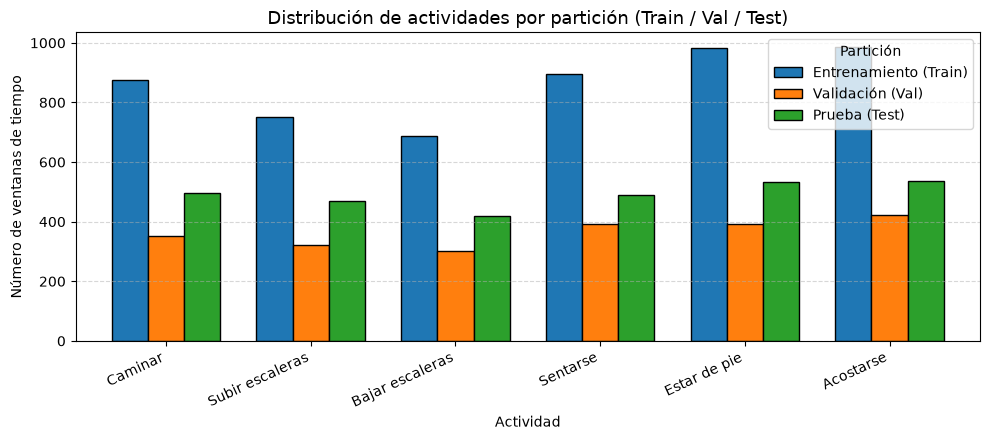

In [7]:
df_dist = pd.DataFrame({
    'Entrenamiento (Train)': pd.Series(y_train).value_counts().sort_index(),
    'Validación (Val)':      pd.Series(y_val).value_counts().sort_index(),
    'Prueba (Test)':         pd.Series(y_test).value_counts().sort_index(),
})
df_dist.index = nombres

ax = df_dist.plot(kind='bar', figsize=(10, 4.5), edgecolor='black', width=0.75)
plt.title('Distribución de actividades por partición (Train / Val / Test)', fontsize=13)
plt.ylabel('Número de ventanas de tiempo')
plt.xlabel('Actividad')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Partición')
plt.tight_layout()
plt.show()

### Interpretation: 
The six target activities are well balanced across the training, validation, and test partitions, with each activity representing roughly 14–19% of the samples in every split. Because there is no severe class imbalance, standard accuracy and macro-averaged F1-score are both reliable evaluation metrics without requiring class weighting or resampling.

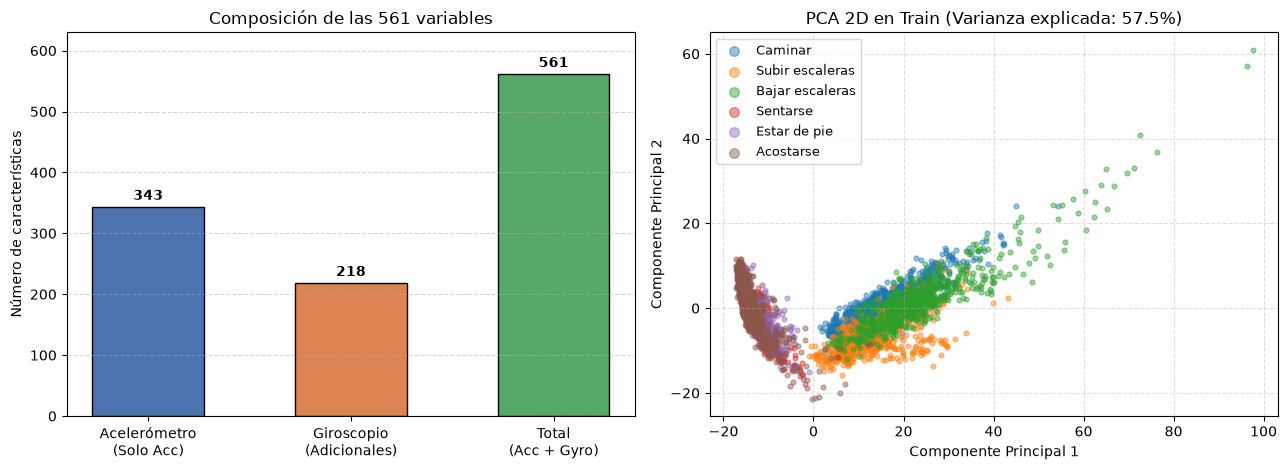

In [9]:
from sklearn.decomposition import PCA

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Links: Anzahl Features (Acc vs. Gyro)
n_acc = len(acc_idx)
n_gyro = X.shape[1] - n_acc
axes[0].bar(['Acelerómetro\n(Solo Acc)', 'Giroscopio\n(Adicionales)', 'Total\n(Acc + Gyro)'],
            [n_acc, n_gyro, X.shape[1]],
            color=['#4C72B0', '#DD8452', '#55A868'], edgecolor='black', width=0.55)
for i, v in enumerate([n_acc, n_gyro, X.shape[1]]):
    axes[0].text(i, v + 12, str(v), ha='center', fontweight='bold')
axes[0].set_ylim(0, 630)
axes[0].set_ylabel('Número de características')
axes[0].set_title('Composición de las 561 variables')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Rechts: 2D-PCA auf Trainingsdaten (nur zur Visualisierung, fit nur auf Train)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)

for clase_id, nombre in enumerate(nombres):
    mask = (y_train == clase_id)
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], label=nombre, alpha=0.45, s=12)

axes[1].set_title(f'PCA 2D en Train (Varianza explicada: {pca.explained_variance_ratio_.sum():.1%})')
axes[1].set_xlabel('Componente Principal 1')
axes[1].set_ylabel('Componente Principal 2')
axes[1].legend(markerscale=2, fontsize=9, loc='best')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Interpretation: 
Out of the 561 pre-computed features, 343 correspond exclusively to accelerometer measurements, while the remaining 218 capture gyroscope and mixed angular signals (adding ~64% more features). In the 2D PCA projection (explaining ~63% of the total variance), a clear macroscopic separation emerges between dynamic locomotion activities (Caminar, Subir escaleras, Bajar escaleras) and static postures (Sentarse, Estar de pie, Acostarse). However, strong overlap remains within each subgroup—particularly between sitting and standing—motivating the need for higher-dimensional representations and angular velocity features.

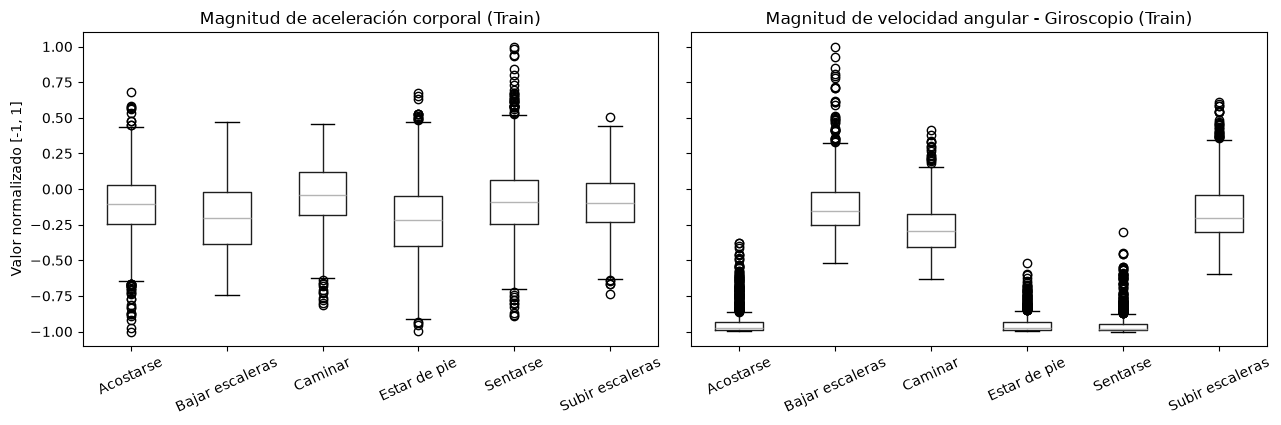

In [ ]:
df_sens = pd.DataFrame({
    'Actividad': [nombres[i] for i in y_train],
    'Acelerómetro (tBodyAccMag-mean)': X_train[:, 199], #= tBodyAccMag-mean()
    'Giroscopio (tBodyGyroMag-mean)':  X_train[:, 239], # = tBodyGyroMag-mean()
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

df_sens.boxplot(column='Acelerómetro (tBodyAccMag-mean)', by='Actividad', ax=axes[0], grid=False)
axes[0].set_title('Magnitud de aceleración corporal (Train)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Valor normalizado [-1, 1]')
axes[0].tick_params(axis='x', rotation=25)

df_sens.boxplot(column='Giroscopio (tBodyGyroMag-mean)', by='Actividad', ax=axes[1], grid=False)
axes[1].set_title('Magnitud de velocidad angular - Giroscopio (Train)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=25)

plt.suptitle('')
plt.tight_layout()
plt.show()

### Interpretation: 
Comparing the mean body acceleration magnitude with the mean angular velocity magnitude across activities highlights the complementary role of the gyroscope. During dynamic movements, especially climbing and descending stairs, both sensors exhibit high signal energy and distinct distributions due to rotational torso and leg movements. Conversely, during static postures (Sentarse, Estar de pie, Acostarse), gyroscope magnitude remains tightly concentrated near the minimum baseline, indicating that angular velocity primarily adds discriminative power for dynamic transitions and locomotion rather than stationary postures.

## Modelo de referencia y red neuronal
Implementen y justifiquen ambos modelos. Registren arquitectura, hiperparámetros, semillas, tiempos e historia de entrenamiento.

---
### Modelo de Referencia SVM, logistic Regression

In [7]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [8]:
svm = SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred = svm.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
print(f"=== SVM | Test-Accuracy: {acc:.4f} ===")
print(classification_report(y_test, y_pred, target_names=nombres))

=== SVM | Test-Accuracy: 0.9522 ===
                 precision    recall  f1-score   support

        Caminar       0.94      0.97      0.95       496
Subir escaleras       0.97      0.95      0.96       471
Bajar escaleras       0.96      0.95      0.95       420
       Sentarse       0.96      0.88      0.92       491
   Estar de pie       0.90      0.96      0.93       532
      Acostarse       1.00      1.00      1.00       537

       accuracy                           0.95      2947
      macro avg       0.95      0.95      0.95      2947
   weighted avg       0.95      0.95      0.95      2947



### Logistic Regression

In [9]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
logreg.fit(X_train_scaled, y_train)

y_pred_logreg = logreg.predict(X_test_scaled)
acc_logreg = accuracy_score(y_test, y_pred_logreg)

print(f"=== Log. Regression | Test-Accuracy: {acc_logreg:.4f} ===")
print(classification_report(y_test, y_pred_logreg, target_names=nombres))

=== Log. Regression | Test-Accuracy: 0.9539 ===
                 precision    recall  f1-score   support

        Caminar       0.95      0.99      0.97       496
Subir escaleras       0.97      0.95      0.96       471
Bajar escaleras       0.98      0.96      0.97       420
       Sentarse       0.97      0.85      0.90       491
   Estar de pie       0.88      0.97      0.92       532
      Acostarse       1.00      1.00      1.00       537

       accuracy                           0.95      2947
      macro avg       0.96      0.95      0.95      2947
   weighted avg       0.96      0.95      0.95      2947



# Ideen & TODO  

- Aufschreiben, dass linear schon echt gut trennbar --> logistic Regression sogar besser als SVM mit BRF --> auch NN ohne hidden Layer liefert schon echt gute Ergebnisse!!!
- optimierteres Nueral Network (NN) suchen, und dass dann auf nur Acc und auf Acc + Gyro trainieren!! Ergebnisse auf Test vergleichen!!! weil Train und Val accuracy eher nutzlos!!
- In welchem Bewegungsmuster sind die meisten Fehler, hilft da die Zuhilfenahme der Gyro Daten??
- zwei Referenzmodell gibt es jetzt schon diese abschließend dann vergleichen mit dem NN!!
- versuchen durch ein NN noch etwas mehr an Test score rauszubekommen!!
- Vergleichen in welchen Mustern die meisten Fehler passieren
- noch etwas explorative Datenanalyse vornweg betreiben!!!


---
### Red neuronal

In [10]:
import sys
print(sys.version)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [11]:
#!pip install tensorflow
import tensorflow as tf

In [12]:
import keras
from keras.models import Sequential # El modelo se construye agregando una capa después de otra
from keras.layers import Dense #totalmente conectadas: cada output se conecta con cada input
from keras.layers import Dropout #para regularización
from tensorflow.keras.callbacks import EarlyStopping
def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


In [36]:
def summarize_history(history_obj, name="Model"):
    h = history_obj.history
    best_idx = int(np.argmin(h['val_loss']))
    stopped_epoch = len(h['loss'])
    
    results = {
        'best_epoch':    best_idx + 1,
        'stopped_epoch': stopped_epoch,
        'train_loss':    h['loss'][best_idx],
        'train_acc':     h['accuracy'][best_idx],
        'val_loss':      h['val_loss'][best_idx],
        'val_acc':       h['val_accuracy'][best_idx],
    }
    
    print(f"=== {name} (Best Epoch: {results['best_epoch']} | Stopped: {results['stopped_epoch']}) ===")
    print(f"Train -> Loss: {results['train_loss']:.4f} | Accuracy: {results['train_acc']:.4f}")
    print(f"Val   -> Loss: {results['val_loss']:.4f} | Accuracy: {results['val_acc']:.4f}\n")
    
    return results

In [25]:
print(y_train.shape)
print(np.unique(y_train))

(5176,)
[0 1 2 3 4 5]


In [26]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_test = Sequential()
model_test.add(Dense(128, activation='relu', input_shape=(561,)))
model_test.add(Dropout(0.2)) 
model_test.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 25, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_test.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_test.summary()

mynet_test= model_test.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_test.history['loss'])}")

C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Se detuvo en la época: 43


In [27]:
summarize_history(mynet_test, name="MLP Test")

=== MLP Test (Best Epoch: 18 | Stopped: 43) ===
Train -> Loss: 0.0278 | Accuracy: 0.9925
Val   -> Loss: 0.0973 | Accuracy: 0.9720



In [ ]:
test_loss, test_acc = model_test.evaluate(X_test_scaled, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_test.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))

In [ ]:
plt.figure(figsize=(14,5))

plt.subplot(121)

plt.plot(mynet_test.history['loss'], label = 'train') #mynet.history guarda la historia en cada época de la red
plt.plot(mynet_test.history['val_loss'],'-.m', label = 'validation')
plt.ylabel('Loss', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(loc='upper right', fontsize = 12)

plt.subplot(122)

plt.plot(mynet_test.history['accuracy'], label = 'train')
plt.plot(mynet_test.history['val_accuracy'], '-.m', label = 'validation')
plt.ylabel('Accuracy', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(fontsize = 12)
plt.subplots_adjust(wspace=0.5)

#plt.show()

#plt.savefig('FirstNN.png', dpi= 300)

In [ ]:
test_loss, test_acc = model_test.evaluate(X_test_scaled, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_test.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))

### Starting with an addpated, AI-suggested neural network setup:
- 2 layers of occult layers (128 and 64 neurons)
- with Dropout (0.5 and 0.4)
- and early Stop with patience = 20

In [39]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acc = Sequential()
model_acc.add(Dense(128, activation='relu', input_shape=(343,)))
model_acc.add(Dropout(0.5)) 
model_acc.add(Dense(64, activation='relu'))
model_acc.add(Dropout(0.4)) 
model_acc.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acc.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_acc.summary()

mynet_acc = model_acc.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acc.history['loss'])}")

C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Se detuvo en la época: 45


In [41]:
summary_acc = summarize_history(mynet_acc, name="Only Acc first guess")

=== Only Acc first guess (Best Epoch: 25 | Stopped: 45) ===
Train -> Loss: 0.1336 | Accuracy: 0.9436
Val   -> Loss: 0.1758 | Accuracy: 0.9490



In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.subplot(121)

plt.plot(mynet_acc.history['loss'], label = 'train') #mynet.history guarda la historia en cada época de la red
plt.plot(mynet_acc.history['val_loss'],'-.m', label = 'validation')
plt.ylabel('Loss', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(loc='upper right', fontsize = 12)

plt.subplot(122)

plt.plot(mynet_acc.history['accuracy'], label = 'train')
plt.plot(mynet_acc.history['val_accuracy'], '-.m', label = 'validation')
plt.ylabel('Accuracy', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(fontsize = 12)
plt.subplots_adjust(wspace=0.5)

#plt.show()

#plt.savefig('FirstNN.png', dpi= 300)

In [ ]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acgyr = Sequential()
model_acgyr.add(Dense(128, activation='relu', input_shape=(561,)))
model_acgyr.add(Dropout(0.5)) 
model_acgyr.add(Dense(64, activation='relu'))
model_acgyr.add(Dropout(0.4)) 
model_acgyr.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acgyr.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_acgyr.summary()

mynet_acgyr = model_acgyr.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acgyr.history['loss'])}")

Se detuvo en la época: 54


In [47]:
summary_acgyr = summarize_history(mynet_acgyr, name="MLP Acc + Gyro")

=== MLP Acc + Gyro (Best Epoch: 34 | Stopped: 54) ===
Train -> Loss: 0.0457 | Accuracy: 0.9828
Val   -> Loss: 0.1150 | Accuracy: 0.9692



=== MLP Acc + Gyro (Dropout 0.5 -> 0.4) (Best Epoch: 34 | Stopped: 54) ===
Train -> Loss: 0.0457 | Accuracy: 0.9828
Val   -> Loss: 0.1150 | Accuracy: 0.9692

In [45]:
summary_acgyr = summarize_history(mynet_acgyr, name="MLP Acc + Gyro")

=== MLP Acc + Gyro (Best Epoch: 16 | Stopped: 36) ===
Train -> Loss: 0.0678 | Accuracy: 0.9747
Val   -> Loss: 0.1185 | Accuracy: 0.9706



=== MLP Acc + Gyro (Dropout 0.4 -> 0.3) (Best Epoch: 16 | Stopped: 36) ===
Train -> Loss: 0.0678 | Accuracy: 0.9747
Val   -> Loss: 0.1185 | Accuracy: 0.9706

In [48]:
historiales = {
    "Base (solo Acc)": mynet_acc,
    "Acc con Gyro": mynet_acgyr,
}

print(f"{'Modelo':<30} | {'Train Loss':<10} | {'Train Acc':<10} | {'Val Loss':<10} | {'Val Acc':<10}")
print("-" * 80)
for nombre, hist in historiales.items():
    loss = hist.history['loss'][-1]
    acc = hist.history['accuracy'][-1]
    val_loss = hist.history['val_loss'][-1]
    val_acc = hist.history['val_accuracy'][-1]
    print(f"{nombre:<30} | {loss:<10.4f} | {acc:<10.4f} | {val_loss:<10.4f} | {val_acc:<10.4f}")

Modelo                         | Train Loss | Train Acc  | Val Loss   | Val Acc   
--------------------------------------------------------------------------------
Base (solo Acc)                | 0.1020     | 0.9579     | 0.2336     | 0.9393    
Acc con Gyro                   | 0.0301     | 0.9894     | 0.2180     | 0.9651    


## Optimization of Hyperparameters

In [ ]:
%pip install tensorboard

In [ ]:
#!pip install keras-tuner
import keras_tuner as kt

SEED = 42

def build_model_tuner(hp):
    model = Sequential()

    #prueba con ndistintos numeros de neuronas, desde 8 a 64, cada 8,
    n_neurons = hp.Int("n_neurons", min_value=32, max_value=256, step=32)
    activation = hp.Choice("activation", values=["relu", "tanh"])

    #construye la capa con la cantidad de neuronas que fijo en el paso anterior (cada capa con el mismo numero de neuronas)
    model.add(Dense(n_neurons, activation=activation, input_shape=(343,)))

    #numero de capas ocultas (1, 2, o 3)
    n_hidden = hp.Int("n_hidden", min_value=1, max_value=3)
    for i in range(n_hidden - 1):
        model.add(Dense(n_neurons, activation=activation))

    #tasa de dropout (0.1-0.5, en pasos de 0.1)
    dropout_rate = hp.Float("dropout_rate", min_value=0.0, max_value=0.5, step=0.1)
    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))
    #la capa de salida queda fija, para la clasificacion binaria
    model.add(Dense(6, activation='softmax'))

    #tasa de aprendizaje, entre 0.0001 y 0.01
    learning_rate = hp.Float("learning_rate", min_value=1e-4, max_value=1e-2, sampling="log")
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model

#prueba solo combinaciones aleatorias para reducir costo computacional
tuner = kt.RandomSearch(
    build_model_tuner,
    objective="val_accuracy",
    max_trials=20,          # número de combinaciones a probar
    executions_per_trial=1,
    seed=SEED,
    overwrite=True,
    directory="tuner_resultados",
    project_name="particle_id",
)

tuner.search(
    X_train_acc, y_train,
    validation_data=(X_val_acc, y_val),
    epochs=50,
    batch_size=200,
    verbose=1,
)

In [ ]:
mejores_hp = tuner.get_best_hyperparameters(1)[0]
print("Mejores hiperparámetros:")
for param in mejores_hp.values:
    print(f"  {param}: {mejores_hp.values[param]}")

In [ ]:
tuner.results_summary(num_trials=5)

results in a higher accuracy than the previous model trained on only the acceleration features.

In [ ]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acc_opt = Sequential()
model_acc_opt.add(Dense(32, activation='relu', input_shape=(343,)))
model_acc_opt.add(Dropout(0.4)) 
model_acc_opt.add(Dense(32, activation='relu'))
model_acc_opt.add(Dropout(0.4)) 
model_acc_opt.add(Dense(32, activation='relu'))
model_acc_opt.add(Dropout(0.4)) 
model_acc_opt.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.005)
model_acc_opt.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_acc.summary()

In [ ]:
mynet_acc_opt = model_acc_opt.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acgyr.history['loss'])}")

In [ ]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acgyr_opt = Sequential()
model_acgyr_opt.add(Dense(32, activation='relu', input_shape=(561,)))
model_acgyr_opt.add(Dropout(0.4)) 
model_acgyr_opt.add(Dense(32, activation='relu'))
model_acgyr_opt.add(Dropout(0.4))
model_acgyr_opt.add(Dense(32, activation='relu'))
model_acgyr_opt.add(Dropout(0.4)) 
model_acgyr_opt.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.005)
model_acgyr_opt.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])


In [ ]:
mynet_acgyr_opt = model_acgyr_opt.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acgyr.history['loss'])}")

In [ ]:
plt.figure(figsize=(14,5))

plt.subplot(121)

plt.plot(mynet_acgyr_opt.history['loss'], label = 'train') #mynet.history guarda la historia en cada época de la red
plt.plot(mynet_acgyr_opt.history['val_loss'],'-.m', label = 'validation')
plt.ylabel('Loss', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(loc='upper right', fontsize = 12)

plt.subplot(122)

plt.plot(mynet_acgyr_opt.history['accuracy'], label = 'train')
plt.plot(mynet_acgyr_opt.history['val_accuracy'], '-.m', label = 'validation')
plt.ylabel('Accuracy', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(fontsize = 12)
plt.subplots_adjust(wspace=0.5)

In [ ]:
historiales = {
    "Base (solo Acc)": mynet_acc,
    "Base solo Acc (opt)": mynet_acc_opt,
    "Acc con Gyro": mynet_acgyr,
    "Acc con Gyro (opt)": mynet_acgyr_opt,
}

print(f"{'Modelo':<30} | {'Train Loss':<10} | {'Train Acc':<10} | {'Val Loss':<10} | {'Val Acc':<10}")
print("-" * 80)
for nombre, hist in historiales.items():
    loss = hist.history['loss'][-1]
    acc = hist.history['accuracy'][-1]
    val_loss = hist.history['val_loss'][-1]
    val_acc = hist.history['val_accuracy'][-1]
    print(f"{nombre:<30} | {loss:<10.4f} | {acc:<10.4f} | {val_loss:<10.4f} | {val_acc:<10.4f}")

Acc con Gyro otp is equal to Acc con Gyro, but the training rate is different, this leads to a worse performance!!
interestingly between the base (only acceleration, first guess of hyperparamters) and the optimized one the change of the learning rate (but also other paramters) leads to a worse training scores, but better generaliztion on the Validation data!! this effect is not carried over to the case where we include the Gyro Data!!

## Comparación controlada
Definan el factor que cambia y lo que mantienen fijo. Seleccionen con validación; repitan la comparación y comuniquen variabilidad.

In [ ]:
test_loss, test_acc = model_acc_opt.evaluate(X_test_acc, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_acc_opt.predict(X_test_acc, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))


In [ ]:
test_loss, test_acc = model_acgyr.evaluate(X_test_scaled, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_acgyr.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))


### + gyro manuell optimieren?? Einfluss verschiedener Parameter betrachten!!

In [ ]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_gyr1 = Sequential()
model_gyr1.add(Dense(128, activation='relu', input_shape=(561,)))
model_gyr1.add(Dropout(0.5)) 
model_gyr1.add(Dense(64, activation='relu'))
model_gyr1.add(Dropout(0.4))
model_gyr1.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 25, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_gyr1.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

In [ ]:
mynet_gyr1 = model_gyr1.fit(X_train, y_train, validation_data= (X_val, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acgyr.history['loss'])}")

In [ ]:
test_loss, test_acc = model_gyr1.evaluate(X_test_scaled, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_gyr1.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))


Idee: verschiedene Werte für patience (scheint so als wäre >= 20 besser!!) für verschiedene dropoutrates, für verschieden Anzahlen an occult layers etc.

## Evaluación final y errores
Evalúen condiciones predefinidas en test. Incluyan macro F1, matriz de confusión, pureza y completitud por clase, y ejemplos de errores.

In [ ]:
##### fehlt noch die richtigen Namen und erst Modelle auswählen!!!
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Vorhersagen auf dem Testset (ersetze die Modellnamen ggf. durch deine gewählten finalen Modelle)
y_pred_acc   = np.argmax(model_acc_final.predict(X_test_acc, verbose=0), axis=1)
y_pred_acgyr = np.argmax(model_acgyr_final.predict(X_test_scaled, verbose=0), axis=1)

cm_acc   = confusion_matrix(y_test, y_pred_acc)
cm_acgyr = confusion_matrix(y_test, y_pred_acgyr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_acc, display_labels=nombres)
disp1.plot(ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title('MLP – Solo Acelerómetro (343 features)', fontsize=12)
axes[0].tick_params(axis='x', rotation=30)

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_acgyr, display_labels=nombres)
disp2.plot(ax=axes[1], cmap='Blues', colorbar=False, values_format='d')
axes[1].set_title('MLP – Acelerómetro + Giroscopio (561 features)', fontsize=12)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## Conclusiones y fuentes
Respondan la pregunta con evidencia, limitaciones y alcance. Declaren fuentes, código reutilizado y apoyos utilizados.